In [1]:
import time
from collections import defaultdict
from itertools import product

import torch
from torch import nn

from pract11.Guia11Reformat.src.ClassifierMLP import ClassifierMLP
from pract11.Guia11Reformat.src.Config import Config
from pract11.Guia11Reformat.src.FashionMNISTData import FashionMNISTData
from pract11.Guia11Reformat.src.Optimizer import create_optimizer
from pract11.Guia11Reformat.src.Trainer import Trainer
from pract11.Guia11Reformat.src.Visualizer import Visualizer


def runExperiment(config, data):
    # Configuración
    device = config.setup()

    if config.show_sample:
        data.inspect_example()

    # Modelo
    torch.manual_seed(config.SEED)

    model = ClassifierMLP(
        p_dropout=config.DROPOUT_P, neuron_1=config.neuron_1, neuron_2=config.neuron_2,
    ).to(device)

    # Comprobar dimensiones
    if config.show_dimentions:
        images, labels = next(iter(data.train_loader))

        with torch.no_grad():
            classifications = model(images.to(device))

        print(f"images.shape: {images.shape}")
        print(f"labels.shape: {labels.shape}")

        n_params = sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        )
        print(f"Parámetros entrenables: {n_params:,}")

        print("\nDimensiones:")
        print("Entrada:", images.shape)
        print("Logits:", classifications.shape)

    # Función de pérdida y optimizador
    loss_fn = nn.CrossEntropyLoss()

    optimizer = create_optimizer(
        model=model,
        optimizer_name=config.OPTIMIZER_NAME,
        lr=config.LEARNING_RATE
    )

    print("\nOptimizador:", config.OPTIMIZER_NAME)
    print("Dropout:", config.DROPOUT_P)

    # Untrained
    if config.show_untrained:
        Visualizer.showPredictions(model, device, data)
    # Entrenamiento
    torch.cuda.reset_peak_memory_stats()

    trainer = Trainer(
        model,
        optimizer,
        loss_fn,
        device,
        config
    )
    start = time.perf_counter()
    trainer.fit(
        data.train_loader,
        data.valid_loader,
        epochs=config.EPOCHS
    )

    training_time = time.perf_counter() - start
    trainer.history["training_time"] = training_time
    print(f"Training time: {training_time:.2f} seconds\n")
    peak_memory = torch.cuda.max_memory_allocated() / (1024 ** 2)
    trainer.history["GPU_max_VRAM"] = peak_memory
    print(f"Peak GPU memory: {peak_memory:.2f} MB")

    # Gráfico de pérdidas
    if config.show_loss: Visualizer.plot_history(trainer.history)

    # Evaluación final
    _, _, confusion_matrix = trainer.test(data.test_loader)

    #Trained
    if config.show_trained:
        Visualizer.showPredictions(model, device, data)
    return trainer, data, confusion_matrix


# ============================================================
# EJECUCIÓN
# ============================================================

def pre_run(expies, data):
    results_together = {}
    for title, exp in expies.items():
        results = {}
        data.reset_loader(batch_size=exp.BATCH_SIZE)  # Reset seed and batch before each experiment
        trainer, data, confusion_matrix = runExperiment(exp, data)
        results[title] = {"trainer": trainer, "data": data, "confusion_matrix": confusion_matrix}
        results_together[title] = {"trainer": trainer, "data": data, "confusion_matrix": confusion_matrix,
                                   "config": exp}
        Visualizer.showExpieResults(results)
    return results_together


data_loaders = FashionMNISTData(
    batch_size=100,
    seed=42, show_dataset_info=False,
)


def viewAftermath(results_together):
    print("\n-----------------------------------Results TOGETHER:-----------------------------------\n")

    groups = defaultdict(dict)

    for title, result in results_together.items():
        config = result["config"]

        key = (
            config.OPTIMIZER_NAME,
            config.LEARNING_RATE
        )

        groups[key][title] = result

    for key, group_results in groups.items():
        print(f"\n-----------------------------------GROUP: {key}:-----------------------------------\n")

        Visualizer.showExpieResults(group_results, show_confusion=False)
        Visualizer.showComparativeTable(group_results)
    print("\n-----------------------------------ALL:-----------------------------------\n")
    Visualizer.showComparativeTable(results_together)


# Obiamente si corremos TODAS las combinaciones tenemos 240 expies que a ~70s mins cada uno son como 5 horas entonces podemos seleccionar parametros que afectan en conjuntos seleccionar el mejor y correr los siguentes. Ejemplo batchSize es importante para Adam entonces corremos opti y batches juntos, selecccionamos el mejor y testeamos los otros.

opti = [
    ("SGD", 0.001),
    ("SGD", 0.01),
    # ("SGD", 0.1),
    # ("Adam", 0.0001),
    # ("Adam", 0.001),
    # ("Adam", 0.01)
]

batches = [
    64,
    100,
    # 256,
    # 512
]

neurons = [
    # (64, 32),
    (128, 64),
    # (256, 128),
    # (512, 256)
]

dropout = [
    # 0,
    0.2,
    # 0.5
]


def gen_expies(opti, batches, neurons, dropout):
    expies = {}

    for (optimizer, lr), batch, (n1, n2), drop in product(
            opti, batches, neurons, dropout
    ):
        title = f"{optimizer}-{lr}/{n1}-{n2}/B{batch}/D{drop}"

        expies[title] = Config(
            lr=lr,
            dropout_p=drop,
            epochs=1,
            optimizer_name=optimizer,
            neuron1=n1,
            neuron2=n2,
            batch_size=batch,
            show_init=True,
            # show_epoch_data=True,
        )
    print(f"\nExperiments: {len(expies)}\n")
    return expies


expies = gen_expies(opti, batches, neurons, dropout)


Experiments: 4




========== CONFIGURATION ==========
Seed:             42
Batch size:       64
Epochs:           1
Dropout:          0.2
Optimizer:        SGD
Learning rate:    0.001
neuron_1:        128
neuron_2:        64

========== ENVIRONMENT ==========
PyTorch: 2.6.0+cu124
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 64
Training time: 12.84 seconds

Peak GPU memory: 18.47 MB

Test CEL: 2.04652
Test accuracy: 41.51%

----------------- SGD-0.001/128-64/B64/D0.2 -----------------


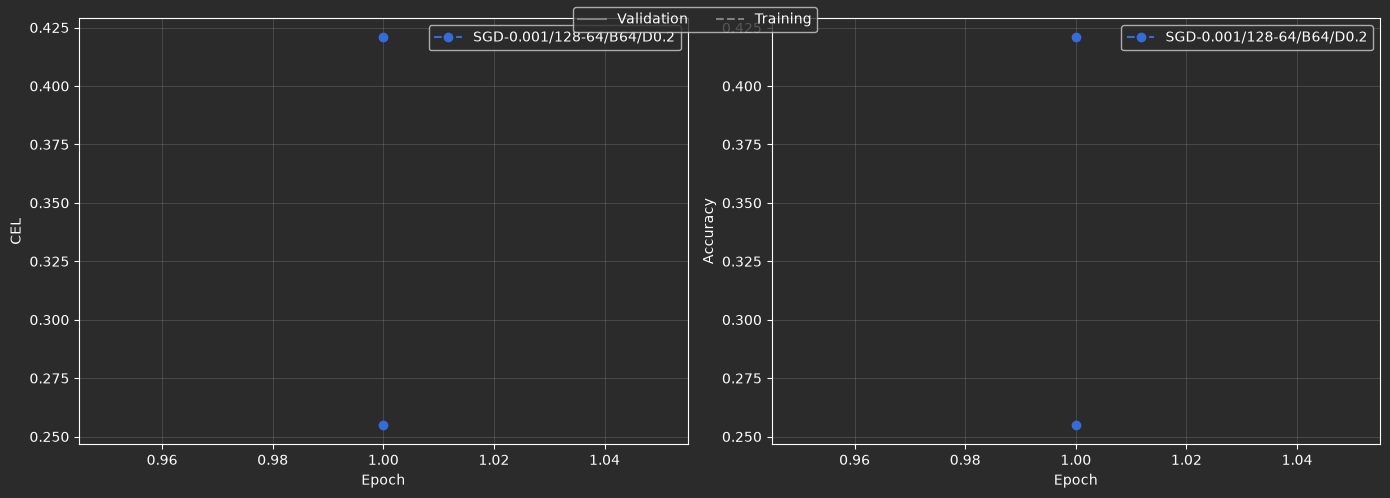

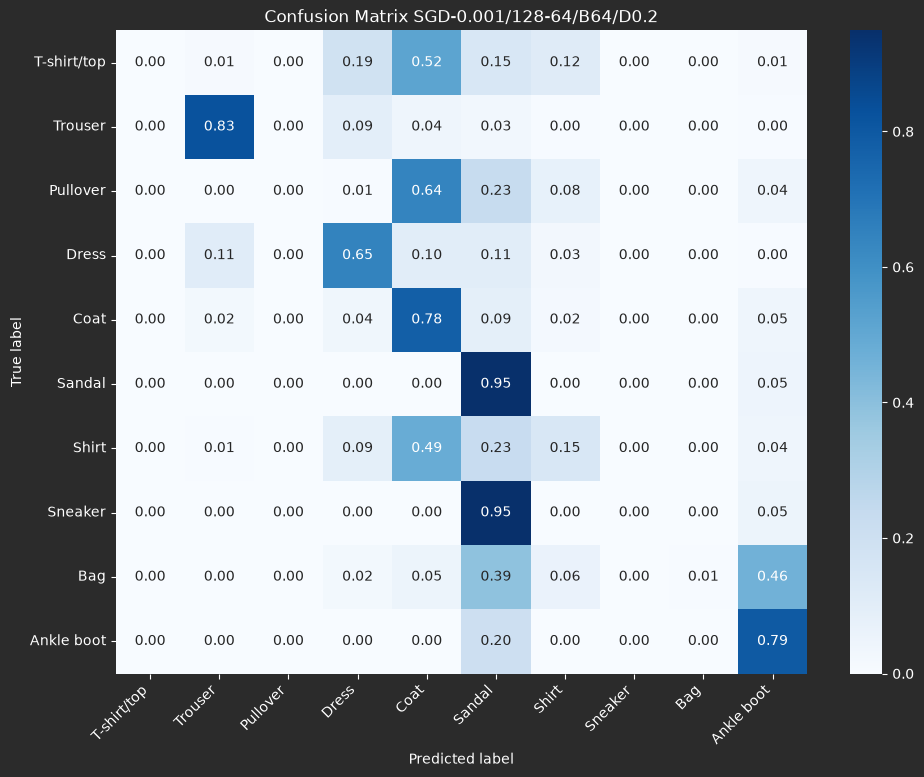


========== CONFIGURATION ==========
Seed:             42
Batch size:       100
Epochs:           1
Dropout:          0.2
Optimizer:        SGD
Learning rate:    0.001
neuron_1:        128
neuron_2:        64

========== ENVIRONMENT ==========
PyTorch: 2.6.0+cu124
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 100
Training time: 10.41 seconds

Peak GPU memory: 19.30 MB

Test CEL: 2.16177
Test accuracy: 37.08%

----------------- SGD-0.001/128-64/B100/D0.2 -----------------


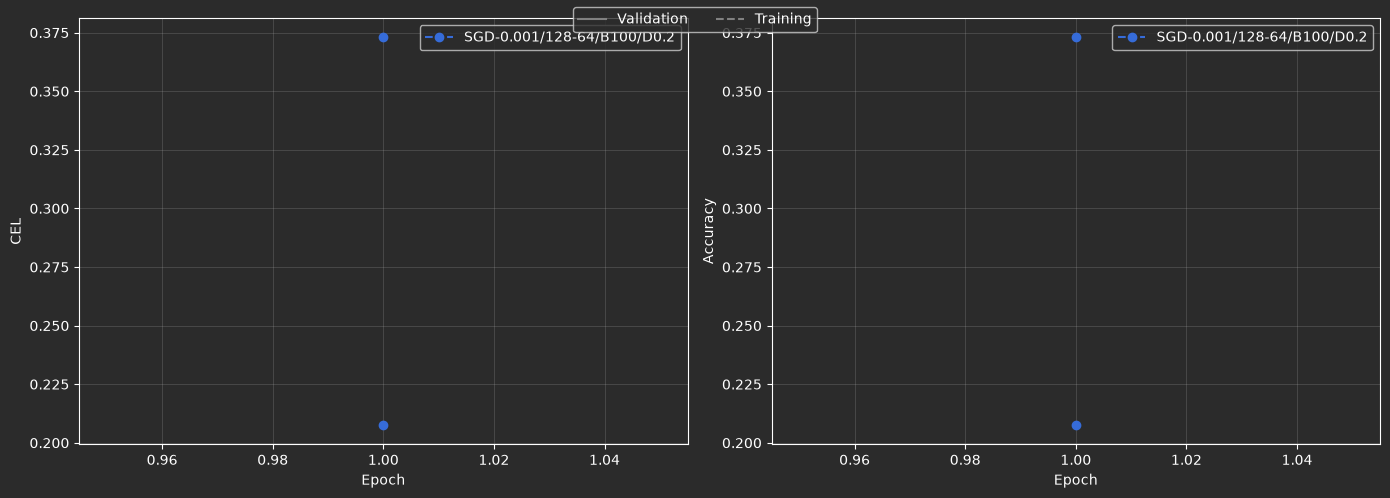

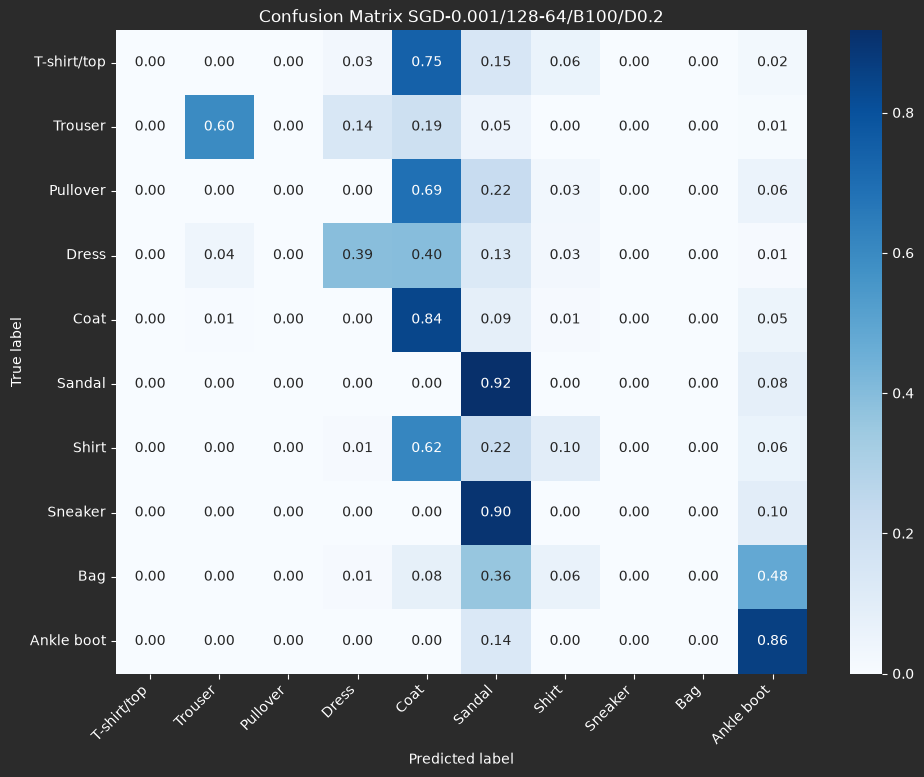


========== CONFIGURATION ==========
Seed:             42
Batch size:       64
Epochs:           1
Dropout:          0.2
Optimizer:        SGD
Learning rate:    0.01
neuron_1:        128
neuron_2:        64

========== ENVIRONMENT ==========
PyTorch: 2.6.0+cu124
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 64
Training time: 10.67 seconds

Peak GPU memory: 20.14 MB

Test CEL: 0.70262
Test accuracy: 74.98%

----------------- SGD-0.01/128-64/B64/D0.2 -----------------


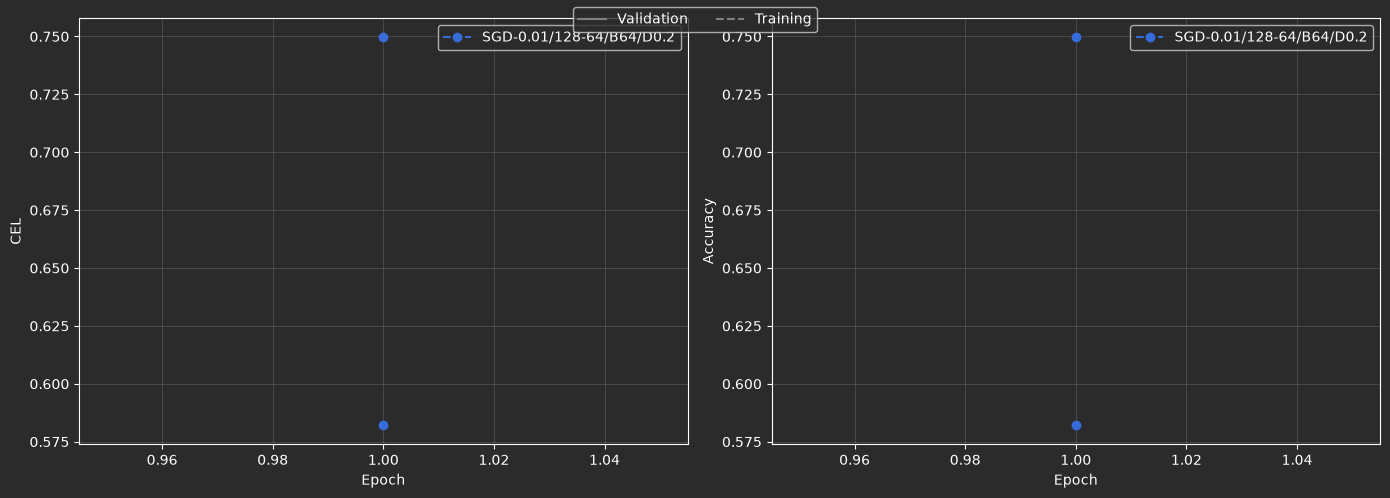

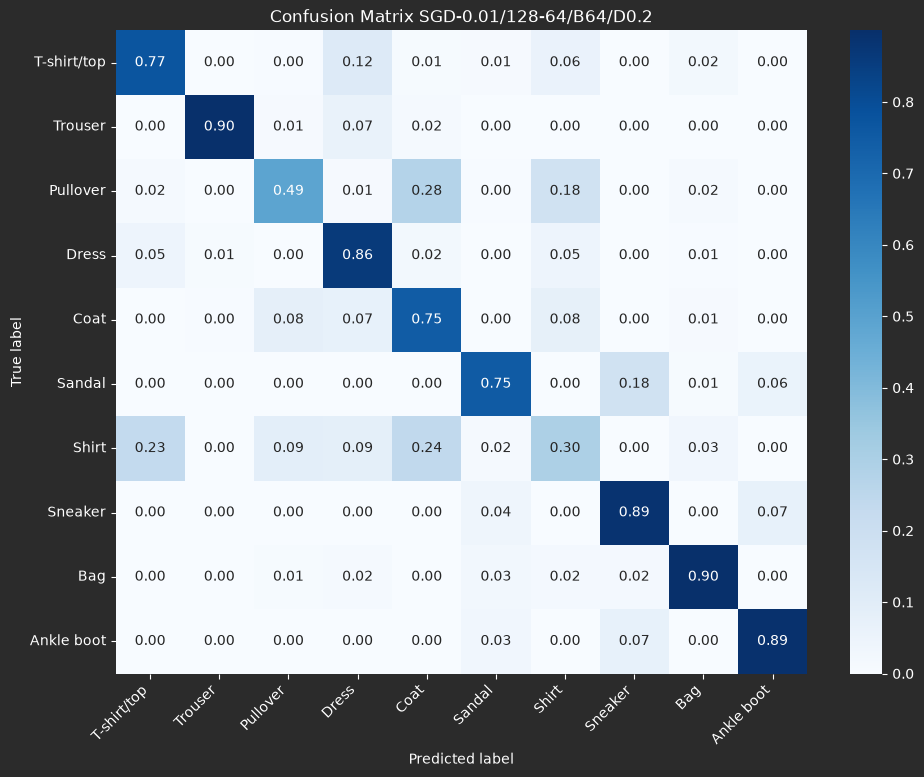


========== CONFIGURATION ==========
Seed:             42
Batch size:       100
Epochs:           1
Dropout:          0.2
Optimizer:        SGD
Learning rate:    0.01
neuron_1:        128
neuron_2:        64

========== ENVIRONMENT ==========
PyTorch: 2.6.0+cu124
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 100
Training time: 10.45 seconds

Peak GPU memory: 20.98 MB

Test CEL: 0.80627
Test accuracy: 73.25%

----------------- SGD-0.01/128-64/B100/D0.2 -----------------


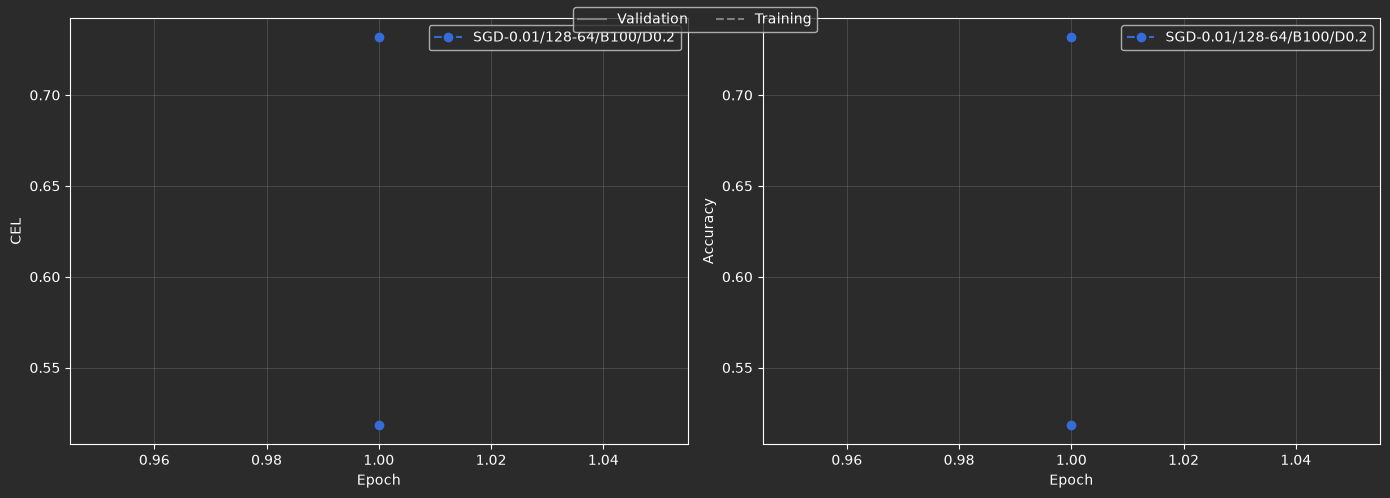

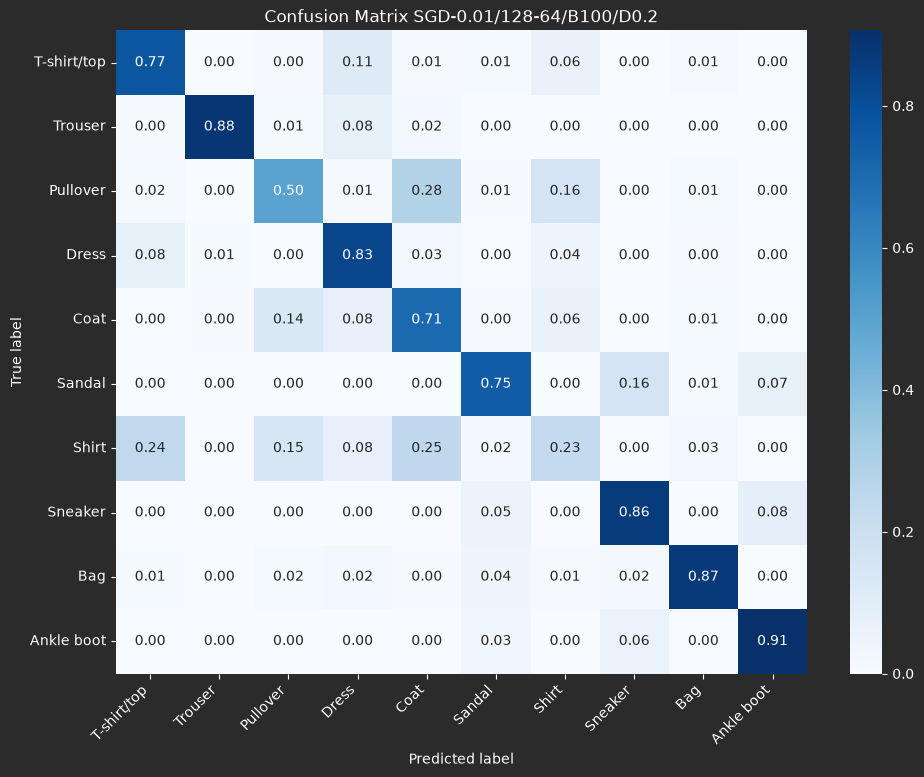

In [2]:
aftermath = pre_run(expies, data_loaders)


-----------------------------------Results TOGETHER:-----------------------------------


-----------------------------------GROUP: ('SGD', 0.001):-----------------------------------

----------------- SGD-0.001/128-64/B64/D0.2 -----------------
----------------- SGD-0.001/128-64/B100/D0.2 -----------------


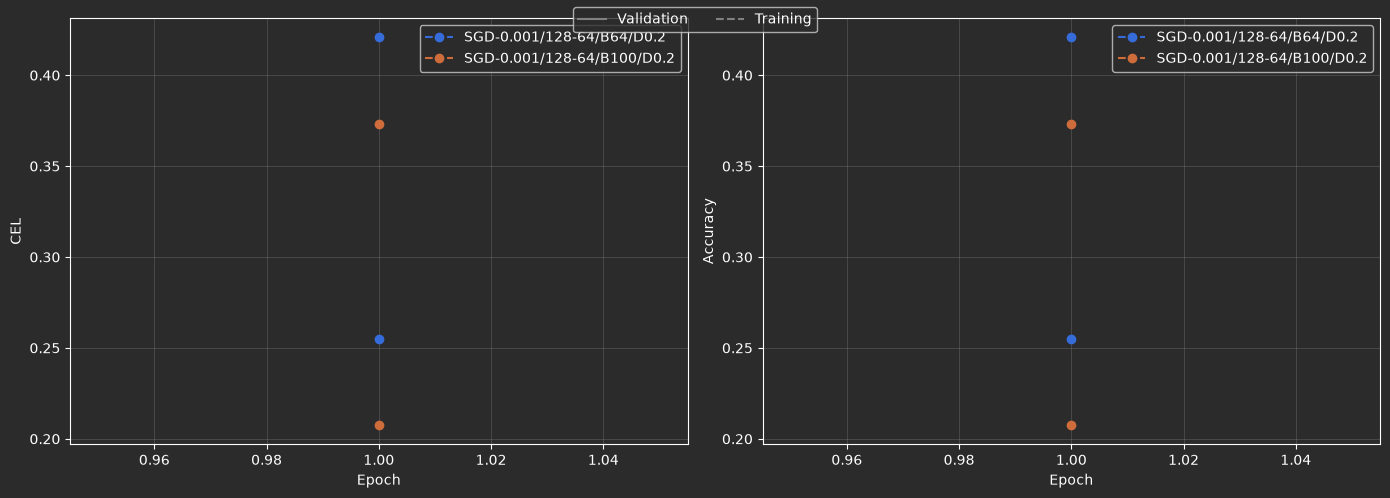

                            Train Loss  Valid Loss  Train Accu  Valid Accu  Test Accu  Mean P  Mean R  Macro F1  Worst Class Recall  TV gap  CM Deviation  Training Time  Max VRAM
SGD-0.001/128-64/B64/D0.2         2.20        2.05        0.25        0.42       0.42    0.49    0.42      0.32                0.00   -0.17          7.45          12.84     18.47
SGD-0.001/128-64/B100/D0.2        2.25        2.16        0.21        0.37       0.37    0.39    0.37      0.28                0.00   -0.17          8.41          10.41     19.30

--- Best experiments ---
Max Test Accu      -> SGD-0.001/128-64/B64/D0.2: 0.4151
Max Valid Accu     -> SGD-0.001/128-64/B64/D0.2: 0.4208
Max Macro F1           -> SGD-0.001/128-64/B64/D0.2: 0.3175
Best Worst-Class Recall -> SGD-0.001/128-64/B64/D0.2: 0.0000
Min CM Deviation       -> SGD-0.001/128-64/B64/D0.2: 7.4470
Min Training Time       -> SGD-0.001/128-64/B100/D0.2: 12.8s
Min VRAM       -> SGD-0.001/128-64/B64/D0.2: 18.46728515625 MB
Min Generalization G

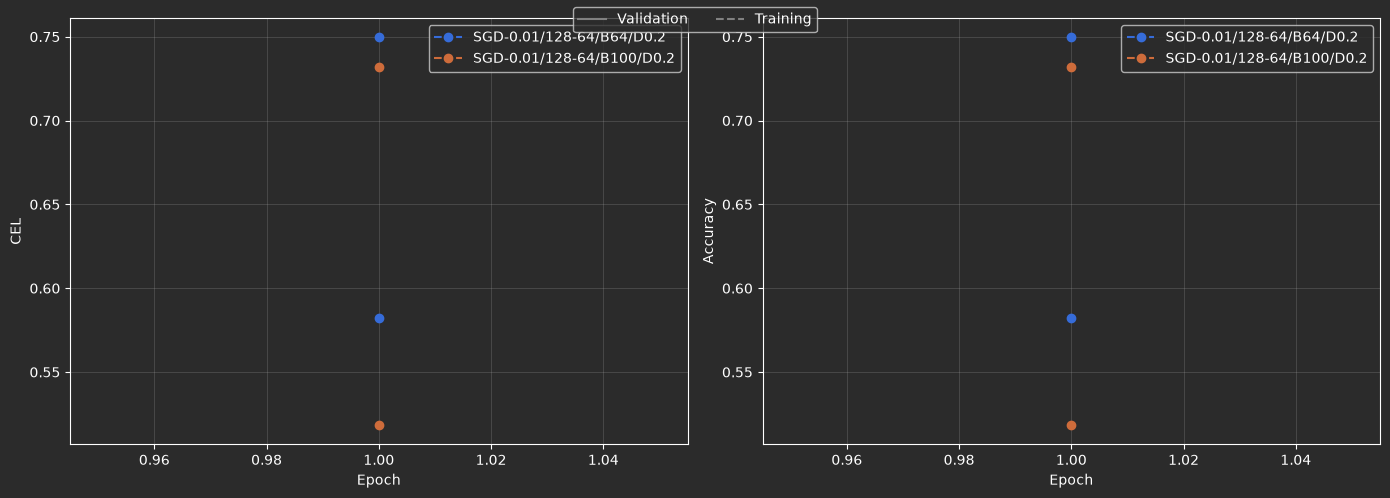

                           Train Loss  Valid Loss  Train Accu  Valid Accu  Test Accu  Mean P  Mean R  Macro F1  Worst Class Recall  TV gap  CM Deviation  Training Time  Max VRAM
SGD-0.01/128-64/B64/D0.2         1.21        0.70        0.58        0.75       0.75    0.75    0.75      0.74                0.30   -0.17          1.33          10.67     20.14
SGD-0.01/128-64/B100/D0.2        1.42        0.80        0.52        0.73       0.73    0.73    0.73      0.72                0.23   -0.21          1.49          10.45     20.98

--- Best experiments ---
Max Test Accu      -> SGD-0.01/128-64/B64/D0.2: 0.7498
Max Valid Accu     -> SGD-0.01/128-64/B64/D0.2: 0.7496
Max Macro F1           -> SGD-0.01/128-64/B64/D0.2: 0.7425
Best Worst-Class Recall -> SGD-0.01/128-64/B64/D0.2: 0.2960
Min CM Deviation       -> SGD-0.01/128-64/B64/D0.2: 1.3320
Min Training Time       -> SGD-0.01/128-64/B100/D0.2: 10.7s
Min VRAM       -> SGD-0.01/128-64/B64/D0.2: 20.13916015625 MB
Min Generalization Gap  -> SGD

In [3]:
viewAftermath(aftermath)